In [1]:
%pip install -q numpy pandas matplotlib pillow opencv-python torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim

SEED = 42
IMAGE_SIZE = 256

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

PRODUCT_ID = "P001"
PRODUCT_NAME = "Teal Geometric Polo"

FRONT_PATH = Path("tshirt_dataset/selected/set_1/front.jpg")
BACK_PATH = Path("tshirt_dataset/selected/set_1/back.jpg")

OUTPUT_DIR = Path("generated_from_scratch") / PRODUCT_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

assert FRONT_PATH.exists(), f"Front image not found: {FRONT_PATH}"
assert BACK_PATH.exists(), f"Back image not found: {BACK_PATH}"

print("Product:", PRODUCT_NAME)
print("Device:", DEVICE)
print("Output directory:", OUTPUT_DIR.resolve())


Product: Teal Geometric Polo
Device: cuda
Output directory: C:\Users\admin\Documents\ann_ajay_project\generated_from_scratch\P001


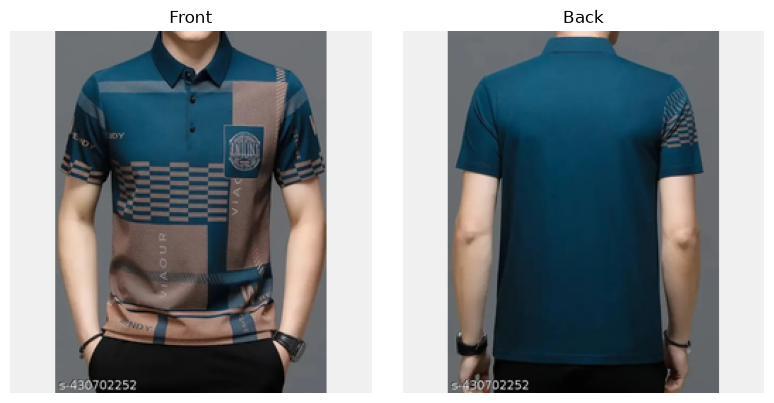

In [3]:
def load_image(path, size=IMAGE_SIZE):
    image = Image.open(path).convert("RGB")
    image.thumbnail((size, size), Image.Resampling.LANCZOS)

    canvas = Image.new("RGB", (size, size), (240, 240, 240))
    x = (size - image.width) // 2
    y = (size - image.height) // 2
    canvas.paste(image, (x, y))

    return np.asarray(canvas)

source_images = {
    "front": load_image(FRONT_PATH),
    "back": load_image(BACK_PATH)
}

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

for ax, (view, image) in zip(axes, source_images.items()):
    ax.imshow(image)
    ax.set_title(view.title())
    ax.axis("off")

plt.tight_layout()
plt.show()


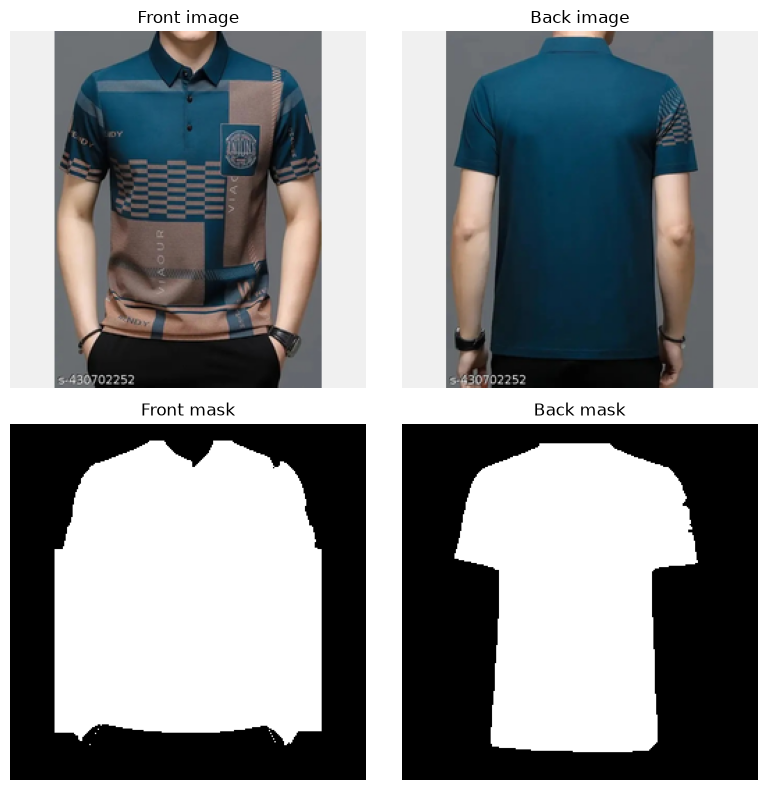

In [4]:

def create_mask(image):
    bgr = cv2.cvtColor(image, cv2.COLOR_RGB2BGR)
    height, width = bgr.shape[:2]

    # Assume the main object is near the centre.
    margin_x = max(5, int(width * 0.08))
    margin_y = max(5, int(height * 0.05))

    rect = (
        margin_x,
        margin_y,
        width - 2 * margin_x,
        height - 2 * margin_y
    )

    mask = np.zeros((height, width), np.uint8)
    background_model = np.zeros((1, 65), np.float64)
    foreground_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        bgr,
        mask,
        rect,
        background_model,
        foreground_model,
        5,
        cv2.GC_INIT_WITH_RECT
    )

    # Definite and probable foreground pixels
    foreground = np.where(
        (mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD),
        255, 0
    ).astype(np.uint8)

    return foreground

masks = {
    view: create_mask(image)
    for view, image in source_images.items()
}

fig, axes = plt.subplots(2, 2, figsize=(8, 8))

for col, view in enumerate(["front", "back"]):
    axes[0, col].imshow(source_images[view])
    axes[0, col].set_title(f"{view.title()} image")
    axes[0, col].axis("off")

    axes[1, col].imshow(masks[view], cmap="gray")
    axes[1, col].set_title(f"{view.title()} mask")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()


In [5]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Linear(64, 2)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)

cnn = SmallCNN().to(DEVICE)

print(cnn)
print("Parameters:", sum(p.numel() for p in cnn.parameters()))


SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)
Parameters: 23714


In [6]:

def make_tensor(image):
    return torch.tensor(
        image.copy(), dtype=torch.float32
    ).permute(2, 0, 1) / 255.0

train_images = []
train_labels = []

for label, view in enumerate(["front", "back"]):
    image = source_images[view]

    for _ in range(30):
        augmented = image.copy()

        if random.random() < 0.5:
            augmented = cv2.flip(augmented, 1)

        angle = random.uniform(-8, 8)
        matrix = cv2.getRotationMatrix2D(
            (IMAGE_SIZE / 2, IMAGE_SIZE / 2), angle, 1.0
        )

        augmented = cv2.warpAffine(
            augmented, matrix,
            (IMAGE_SIZE, IMAGE_SIZE),
            borderMode=cv2.BORDER_REFLECT
        )

        brightness = random.uniform(0.9, 1.1)
        augmented = np.clip(
            augmented.astype(np.float32) * brightness,
            0, 255
        ).astype(np.uint8)

        train_images.append(make_tensor(augmented))
        train_labels.append(label)

X_train = torch.stack(train_images).to(DEVICE)
y_train = torch.tensor(train_labels, dtype=torch.long).to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn.parameters(), lr=0.001)

EPOCHS = 8
cnn.train()

for epoch in range(EPOCHS):
    optimizer.zero_grad()

    logits = cnn(X_train)
    loss = criterion(logits, y_train)

    loss.backward()
    optimizer.step()

    if (epoch + 1) % 2 == 0:
        print(f"Epoch {epoch + 1}/{EPOCHS}, loss={loss.item():.4f}")

cnn.eval()


Epoch 2/8, loss=0.6892
Epoch 4/8, loss=0.6834
Epoch 6/8, loss=0.6767
Epoch 8/8, loss=0.6689


SmallCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Linear(in_features=64, out_features=2, bias=True)
)

In [7]:

cnn_features = {}
colour_features = {}

with torch.inference_mode():
    for view, image in source_images.items():
        tensor = make_tensor(image).unsqueeze(0).to(DEVICE)
        features = cnn.features(tensor).flatten(1).squeeze(0)
        cnn_features[view] = features.cpu().numpy()

        hist_parts = []
        for channel in range(3):
            hist = cv2.calcHist(
                [image], [channel], None, [4], [0, 256]
            ).flatten()

            hist = hist / (hist.sum() + 1e-8)
            hist_parts.extend(hist)

        colour_features[view] = np.array(
            hist_parts, dtype=np.float32
        )

    print("CNN feature shape:", cnn_features["front"].shape)
    print("Colour feature shape:", colour_features["front"].shape)


CNN feature shape: (64,)
Colour feature shape: (12,)


In [8]:

def combine_features(view):
    cnn_vector = cnn_features[view].astype(np.float32)
    colour_vector = colour_features[view].astype(np.float32)

    cnn_vector /= np.linalg.norm(cnn_vector) + 1e-8
    colour_vector /= np.linalg.norm(colour_vector) + 1e-8

    return np.concatenate([cnn_vector, colour_vector])

front_vector = combine_features("front")
back_vector = combine_features("back")

# Median thresholding produces bipolar patterns
front_pattern = np.where(
    front_vector >= np.median(front_vector), 1.0, -1.0
)
back_pattern = np.where(
    back_vector >= np.median(back_vector), 1.0, -1.0
)

# Hebbian associative memory
bam_weights = np.outer(front_pattern, back_pattern)

# Recall back pattern from the front pattern
back_recalled = np.where(
    front_pattern @ bam_weights >= 0, 1.0, -1.0
)

recall_agreement = np.mean(back_recalled == back_pattern)

print("BAM matrix shape:", bam_weights.shape)
print("Recall agreement:", round(float(recall_agreement), 3))


BAM matrix shape: (76, 76)
Recall agreement: 1.0


In [9]:

def generate_geometric_design(image, mask, seed=42, design_id=0):
    rng = np.random.default_rng(seed + design_id)

    base = image.astype(np.float32).copy()
    mask_float = mask.astype(np.float32) / 255.0

    height, width = mask.shape
    pattern = np.zeros_like(base, dtype=np.uint8)

    # Two design colours: copper and light teal
    copper = (190, 115, 65)
    light_teal = (145, 205, 190)

    spacing = int(rng.integers(22, 35))
    offset = int(rng.integers(0, spacing))

    # Diagonal geometric lines
    for x in range(-height, width, spacing):
        colour = copper if rng.random() < 0.5 else light_teal

        cv2.line(
            pattern,
            (x + offset, 0),
            (x + height + offset, height),
            colour,
            thickness=2,
            lineType=cv2.LINE_AA
        )

    # Add geometric circles
    for _ in range(20):
        x = int(rng.integers(0, width))
        y = int(rng.integers(0, height))
        radius = int(rng.integers(3, 9))

        cv2.circle(
            pattern, (x, y), radius, copper, 2,
            lineType=cv2.LINE_AA
        )

    # Restrict the design to the segmented foreground
    alpha = (mask_float * 0.38)[..., None]

    result = (
        base * (1 - alpha) +
        pattern.astype(np.float32) * alpha
    )

    return np.clip(result, 0, 255).astype(np.uint8)

generated_images = {}

for view in ["front", "back"]:
    generated = generate_geometric_design(
        source_images[view],
        masks[view],
        seed=SEED,
        design_id=0
    )

    generated_images[view] = generated

    output_path = OUTPUT_DIR / f"{view}_generated.png"
    Image.fromarray(generated).save(output_path)

    print("Saved:", output_path)


Saved: generated_from_scratch\P001\front_generated.png
Saved: generated_from_scratch\P001\back_generated.png


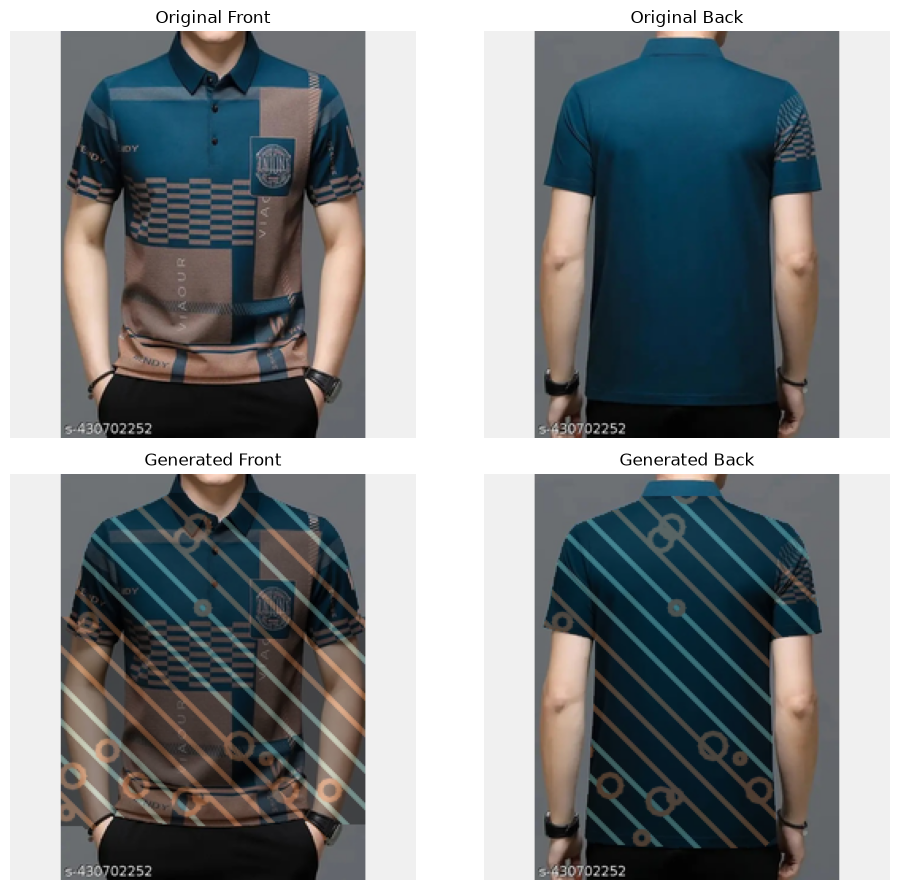

In [10]:

fig, axes = plt.subplots(2, 2, figsize=(10, 9))

for col, view in enumerate(["front", "back"]):
    axes[0, col].imshow(source_images[view])
    axes[0, col].set_title(f"Original {view.title()}")
    axes[0, col].axis("off")

    axes[1, col].imshow(generated_images[view])
    axes[1, col].set_title(f"Generated {view.title()}")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()
